In [1]:
import pandas as pd

# Load your SFE dataset
df = pd.read_excel("Composition_SFE_Dataset_old.xlsx")

# Show first few rows (optional)
print(df.head())

# Check if SFE column exists
print("Columns in the dataset:", df.columns.tolist())

# Compute min and max
min_sfe = df["SFE"].min()
max_sfe = df["SFE"].max()

print("\n====== SFE Range in Dataset ======")
print(f"Minimum SFE: {min_sfe:.4f}")
print(f"Maximum SFE: {max_sfe:.4f}")


         Fe        Mn        Ni        Co        Cr         V        Al  \
0  0.142857  0.142857  0.142857  0.142857  0.142857  0.142857  0.142857   
1  0.202866  0.025391  0.365391  0.296460  0.054369  0.032077  0.023446   
2  0.182712  0.006847  0.510895  0.071240  0.161001  0.038695  0.028610   
3  0.035201  0.015630  0.724721  0.141416  0.030501  0.008102  0.044428   
4  0.227773  0.014224  0.531015  0.100751  0.063310  0.012472  0.050456   

          SFE  
0   51.649535  
1   26.631791  
2   47.896873  
3  134.401773  
4   70.897057  
Columns in the dataset: ['Fe', 'Mn', 'Ni', 'Co', 'Cr', 'V', 'Al', 'SFE']

====== SFE Range in Dataset ======
Minimum SFE: -315.1430
Maximum SFE: 148.8960


In [2]:
# ============================================================
# FULL WORKING CODE (ALL 7 elements present)
# Target SFE range: 15–25 mJ/m^2 (TRIP/TWIP window)
# Constraints:
#   - ALL 7 elements are present (non-zero)
#   - Each element: 0.05 to 0.35
#   - Sum of all fractions = 1.0
# Uses your trained model: stacked_sfe_model_PT.pkl (joblib)
# Saves top candidates to Excel
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.neighbors import NearestNeighbors

# =========================
# 0) SETTINGS
# =========================
MODEL_PATH = r"D:\Uddipta\PT_model\stacked_sfe_model_PT.pkl"  # <-- change if needed
DATA_PATH  = r"Composition_SFE_Dataset_old.xlsx"             # <-- change if needed

feature_cols = ["Fe", "Mn", "Ni", "Co", "Cr", "V", "Al"]

# ---- ALL 7 present ----
K_ACTIVE = 7                 # all 7 elements present (no zeros)
MIN_FRAC_ACTIVE = 0.05       # each element >= 0.05
MAX_FRAC_ACTIVE = 0.35       # each element <= 0.35
SUM_TARGET = 1.0             # sum must be exactly 1

# ---- optimization ----
POP_SIZE = 30
ITERATIONS = 500
SEED = 42

# ---- target window ----
LOW_SFE  = 15.0
HIGH_SFE = 25.0

# ---- novelty penalty (optional) ----
USE_NOVELTY_PENALTY = True
NOVELTY_PERCENTILE = 95      # 95 or 99
LAMBDA_NOVELTY = 50.0        # penalty strength (tune 10–200)

# ---- output ----
OUTPUT_XLSX = "GWO_TRIP_TWIP_candidates_7of7.xlsx"
TOP_N_SAVE = 50

np.random.seed(SEED)


# =========================
# 1) LOAD DATA + MODEL
# =========================
df = pd.read_excel(DATA_PATH)

missing = [c for c in feature_cols + ["SFE"] if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in dataset: {missing}")

X_train = df[feature_cols].copy().values
y_train = df["SFE"].copy().values

print("Dataset shape:", df.shape)
print("SFE range in dataset:", float(np.min(y_train)), "to", float(np.max(y_train)))

stacked_model = joblib.load(MODEL_PATH)
print("✅ Model loaded:", MODEL_PATH)

# sanity check
test_pred = float(stacked_model.predict(df[feature_cols].iloc[[0]])[0])
print("Example prediction on first row:", test_pred)


# =========================
# 2) NOVELTY MODEL (kNN distance)
# =========================
nn = None
thr = None

if USE_NOVELTY_PENALTY:
    nn = NearestNeighbors(n_neighbors=2, metric="euclidean")
    nn.fit(X_train)

    dists, _ = nn.kneighbors(X_train, n_neighbors=2)
    train_nn_dist = dists[:, 1]

    thr = float(np.percentile(train_nn_dist, 99 if NOVELTY_PERCENTILE == 99 else 95))
    print(f"Novelty threshold (train NN dist p{NOVELTY_PERCENTILE}): {thr:.6f}")


# =========================
# 3) CONSTRAINT HELPERS
# =========================
def make_feasible_all7(vec,
                       min_a=MIN_FRAC_ACTIVE,
                       max_a=MAX_FRAC_ACTIVE,
                       sum_target=SUM_TARGET,
                       max_iter=4000,
                       eps=1e-12):
    """
    Projects any vector -> feasible composition with:
      - ALL 7 elements active (no zeros)
      - each entry in [min_a, max_a]
      - sum = sum_target
    Uses iterative clip + redistribute (water-filling).
    """
    x = np.array(vec, dtype=float).copy()
    x = np.abs(x)

    n = x.size
    if n != len(feature_cols):
        raise ValueError("Vector dimension mismatch.")

    # If all tiny, start uniform
    if x.sum() < eps:
        x = np.ones(n) / n
    else:
        x = x / x.sum()

    # start from sum_target
    x *= sum_target

    for _ in range(max_iter):
        # clip
        x = np.clip(x, min_a, max_a)
        s = x.sum()
        diff = sum_target - s

        if abs(diff) < 1e-10:
            break

        # who can move?
        if diff > 0:
            free = x < (max_a - 1e-12)
        else:
            free = x > (min_a + 1e-12)

        if not np.any(free):
            break

        x[free] += diff / free.sum()

    # final clip + exact renormalize
    x = np.clip(x, min_a, max_a)
    s = x.sum()
    if s > eps:
        x *= (sum_target / s)

    # final safety (keep within bounds)
    x = np.clip(x, min_a, max_a)
    # tiny correction to ensure exact sum=1 (numerical)
    x *= (sum_target / x.sum())

    return x


def predict_sfe(x):
    df_tmp = pd.DataFrame([x], columns=feature_cols)
    return float(stacked_model.predict(df_tmp)[0])


def window_loss(sfe, low=LOW_SFE, high=HIGH_SFE):
    if low <= sfe <= high:
        return 0.0
    if sfe < low:
        return low - sfe
    return sfe - high


def novelty_penalty(x, thr_local=thr, lam=LAMBDA_NOVELTY):
    if (not USE_NOVELTY_PENALTY) or (nn is None) or (thr_local is None):
        return 0.0
    d, _ = nn.kneighbors([x], n_neighbors=1)
    d = float(d[0][0])
    if d <= thr_local:
        return 0.0
    return lam * (d - thr_local)


# =========================
# 4) OBJECTIVE (inverse design to hit 15–25 window)
# =========================
def objective(vec):
    x = make_feasible_all7(vec)
    sfe = predict_sfe(x)
    return window_loss(sfe) + novelty_penalty(x)


# =========================
# 5) GREY WOLF OPTIMIZER
# =========================
class GreyWolfOptimizer:
    def __init__(self, obj_func, dim, pop_size=POP_SIZE, iterations=ITERATIONS):
        self.obj_func = obj_func
        self.dim = dim
        self.pop_size = pop_size
        self.iterations = iterations
        self.positions = np.random.rand(self.pop_size, self.dim)
        self.alpha = None
        self.beta = None
        self.delta = None
        self.history_best = []

    def optimize(self, verbose=True):
        for t in range(self.iterations):
            fitness = np.array([self.obj_func(p) for p in self.positions], dtype=float)

            idx = np.argsort(fitness)
            self.alpha = self.positions[idx[0]].copy()
            self.beta  = self.positions[idx[1]].copy()
            self.delta = self.positions[idx[2]].copy()

            best = float(fitness[idx[0]])
            self.history_best.append(best)

            if verbose and (t % 50 == 0 or t == self.iterations - 1):
                x_best = make_feasible_all7(self.alpha)
                sfe_best = predict_sfe(x_best)
                print(f"Iter {t:4d} | best loss: {best:.6f} | pred SFE: {sfe_best:.3f}")

            a = 2 * (1 - t / self.iterations)

            for i in range(self.pop_size):
                for j in range(self.dim):
                    # alpha
                    r1, r2 = np.random.rand(), np.random.rand()
                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2
                    D_alpha = abs(C1 * self.alpha[j] - self.positions[i, j])
                    X1 = self.alpha[j] - A1 * D_alpha

                    # beta
                    r1, r2 = np.random.rand(), np.random.rand()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2
                    D_beta = abs(C2 * self.beta[j] - self.positions[i, j])
                    X2 = self.beta[j] - A2 * D_beta

                    # delta
                    r1, r2 = np.random.rand(), np.random.rand()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2
                    D_delta = abs(C3 * self.delta[j] - self.positions[i, j])
                    X3 = self.delta[j] - A3 * D_delta

                    self.positions[i, j] = (X1 + X2 + X3) / 3.0

                self.positions[i] = np.clip(self.positions[i], 0.0, 1.0)

        x_best = make_feasible_all7(self.alpha)
        sfe_best = predict_sfe(x_best)
        return x_best, sfe_best, self.history_best


# =========================
# 6) RUN OPTIMIZATION
# =========================
gwo = GreyWolfOptimizer(obj_func=objective, dim=len(feature_cols),
                        pop_size=POP_SIZE, iterations=ITERATIONS)

best_comp, best_sfe, history = gwo.optimize(verbose=True)

print("\n========== BEST COMPOSITION (ALL 7 ELEMENTS PRESENT) ==========")
best_series = pd.Series(best_comp, index=feature_cols)
print(best_series)
print("Sum:", float(best_series.sum()))
print("Predicted SFE:", float(best_sfe))
print(f"Within [{LOW_SFE}, {HIGH_SFE}]?:", (LOW_SFE <= best_sfe <= HIGH_SFE))


# =========================
# 7) SAVE TOP CANDIDATES
# =========================
records = []
for raw in gwo.positions:
    x = make_feasible_all7(raw)
    sfe = predict_sfe(x)
    loss = window_loss(sfe) + novelty_penalty(x)

    rec = {feature_cols[i]: x[i] for i in range(len(feature_cols))}
    rec["Predicted_SFE"] = sfe
    rec["WindowLoss"] = window_loss(sfe)
    if USE_NOVELTY_PENALTY:
        d, _ = nn.kneighbors([x], n_neighbors=1)
        rec["NN_dist"] = float(d[0][0])
        rec[f"is_novel_p{NOVELTY_PERCENTILE}"] = (rec["NN_dist"] > thr)
    else:
        rec["NN_dist"] = np.nan
        rec[f"is_novel_p{NOVELTY_PERCENTILE}"] = False

    rec["TotalLoss"] = loss
    records.append(rec)

res = pd.DataFrame(records)
res = res.sort_values(["WindowLoss", "TotalLoss", "Predicted_SFE"],
                      ascending=[True, True, True]).reset_index(drop=True)

res_top = res.head(TOP_N_SAVE).copy()
res_top.to_excel(OUTPUT_XLSX, index=False)

print(f"\n✅ Saved top {len(res_top)} candidates to: {OUTPUT_XLSX}")
print("\nTop 10 candidates preview:")
print(res_top.head(10))


Dataset shape: (426, 8)
SFE range in dataset: -315.143 to 148.896
✅ Model loaded: D:\Uddipta\PT_model\stacked_sfe_model_PT.pkl
Example prediction on first row: 51.01189679532495
Novelty threshold (train NN dist p95): 0.070328
Iter    0 | best loss: 4.324020 | pred SFE: 21.357
Iter   50 | best loss: 2.398110 | pred SFE: 21.873
Iter  100 | best loss: 2.803801 | pred SFE: 21.832
Iter  150 | best loss: 2.388769 | pred SFE: 21.683
Iter  200 | best loss: 1.682368 | pred SFE: 22.360
Iter  250 | best loss: 1.651771 | pred SFE: 24.627
Iter  300 | best loss: 1.287727 | pred SFE: 23.943
Iter  350 | best loss: 1.494129 | pred SFE: 24.132
Iter  400 | best loss: 1.066459 | pred SFE: 24.737
Iter  450 | best loss: 0.915271 | pred SFE: 25.119
Iter  499 | best loss: 0.786292 | pred SFE: 24.987

========== BEST COMPOSITION (ALL 7 ELEMENTS PRESENT) ==========
Fe    0.141645
Mn    0.183906
Ni    0.110459
Co    0.136016
Cr    0.148215
V     0.092047
Al    0.187712
dtype: float64
Sum: 1.0
Predicted SFE: 24.9

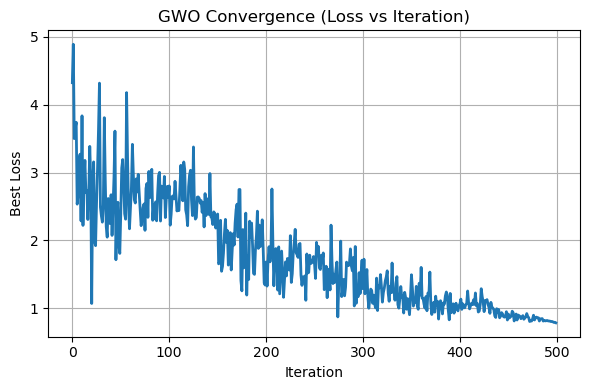

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(history, linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Best Loss")
plt.title("GWO Convergence (Loss vs Iteration)")
plt.grid(True)
plt.tight_layout()
plt.show()

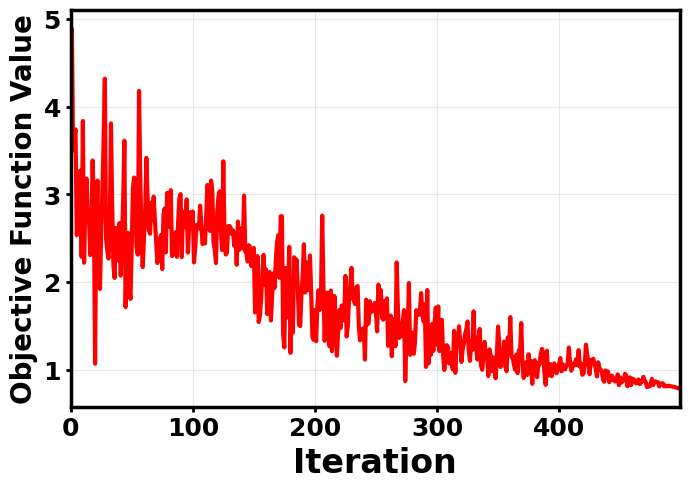

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,5))

ax.plot(history, color='red', linewidth=3)

ax.set_xlabel("Iteration", fontsize=24, fontweight='bold')
#ax.set_ylabel("Loss Function", fontsize=20, fontweight='bold')
ax.set_ylabel("Objective Function Value", fontsize=20, fontweight='bold')

ax.set_xlim(0, len(history)-1)

ax.tick_params(axis='both', labelsize=18, width=2)
for tick in ax.get_xticklabels()+ax.get_yticklabels():
    tick.set_fontweight('bold')

ax.grid(True, alpha=0.3)

for spine in ax.spines.values():
    spine.set_linewidth(2.5)

plt.tight_layout()
plt.savefig("Loss_vs_iteration.tif", dpi=600,
            format="tiff", pil_kwargs={"compression":"tiff_lzw"})
plt.show()

In [6]:
###########################For composition evoludtion#################


In [7]:
# =========================
# GREY WOLF OPTIMIZER WITH HISTORY
# =========================

class GreyWolfOptimizer:
    def __init__(self, obj_func, dim, pop_size=POP_SIZE, iterations=ITERATIONS):
        self.obj_func = obj_func
        self.dim = dim
        self.pop_size = pop_size
        self.iterations = iterations

        self.positions = np.random.rand(self.pop_size, self.dim)

        self.alpha = None
        self.beta = None
        self.delta = None

        self.history_best = []
        self.history_sfe = []
        self.history_composition = []

    def optimize(self, verbose=True):
        for t in range(self.iterations):

            fitness = np.array([self.obj_func(p) for p in self.positions], dtype=float)

            idx = np.argsort(fitness)
            self.alpha = self.positions[idx[0]].copy()
            self.beta  = self.positions[idx[1]].copy()
            self.delta = self.positions[idx[2]].copy()

            best_loss = float(fitness[idx[0]])
            x_best = make_feasible_all7(self.alpha)
            sfe_best = predict_sfe(x_best)

            # Store history
            self.history_best.append(best_loss)
            self.history_sfe.append(sfe_best)
            self.history_composition.append(x_best.copy())

            if verbose and (t % 50 == 0 or t == self.iterations - 1):
                print(f"Iter {t:4d} | Objective: {best_loss:.6f} | Pred SFE: {sfe_best:.3f}")

            a = 2 * (1 - t / self.iterations)

            for i in range(self.pop_size):
                for j in range(self.dim):

                    # Alpha wolf
                    r1, r2 = np.random.rand(), np.random.rand()
                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2
                    D_alpha = abs(C1 * self.alpha[j] - self.positions[i, j])
                    X1 = self.alpha[j] - A1 * D_alpha

                    # Beta wolf
                    r1, r2 = np.random.rand(), np.random.rand()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2
                    D_beta = abs(C2 * self.beta[j] - self.positions[i, j])
                    X2 = self.beta[j] - A2 * D_beta

                    # Delta wolf
                    r1, r2 = np.random.rand(), np.random.rand()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2
                    D_delta = abs(C3 * self.delta[j] - self.positions[i, j])
                    X3 = self.delta[j] - A3 * D_delta

                    self.positions[i, j] = (X1 + X2 + X3) / 3.0

                self.positions[i] = np.clip(self.positions[i], 0.0, 1.0)

        x_best = make_feasible_all7(self.alpha)
        sfe_best = predict_sfe(x_best)

        return x_best, sfe_best, self.history_best

In [8]:
gwo = GreyWolfOptimizer(
    obj_func=objective,
    dim=len(feature_cols),
    pop_size=POP_SIZE,
    iterations=ITERATIONS
)

best_comp, best_sfe, history = gwo.optimize(verbose=True)

Iter    0 | Objective: 4.009935 | Pred SFE: 21.350
Iter   50 | Objective: 2.109701 | Pred SFE: 23.489
Iter  100 | Objective: 1.687110 | Pred SFE: 23.406
Iter  150 | Objective: 1.495781 | Pred SFE: 23.866
Iter  200 | Objective: 1.317334 | Pred SFE: 23.871
Iter  250 | Objective: 1.792655 | Pred SFE: 24.197
Iter  300 | Objective: 1.461121 | Pred SFE: 23.803
Iter  350 | Objective: 0.959450 | Pred SFE: 24.489
Iter  400 | Objective: 0.966965 | Pred SFE: 25.010
Iter  450 | Objective: 0.932807 | Pred SFE: 24.344
Iter  499 | Objective: 0.756912 | Pred SFE: 24.964


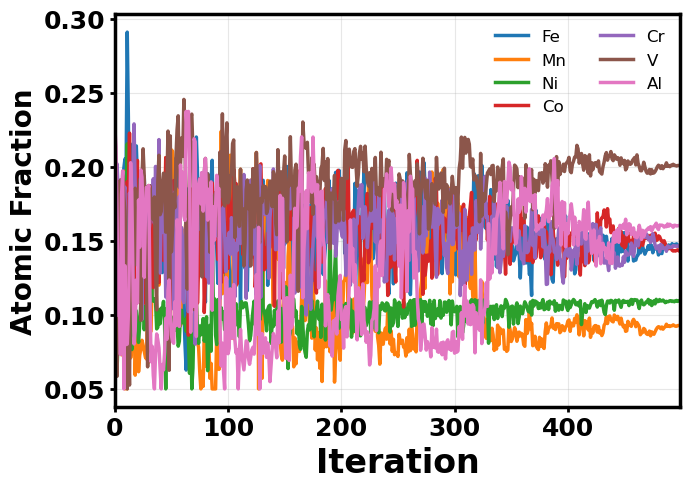

In [9]:
import numpy as np
import matplotlib.pyplot as plt

comp_history = np.array(gwo.history_composition)

fig, ax = plt.subplots(figsize=(7,5))

for i, elem in enumerate(feature_cols):
    ax.plot(comp_history[:, i], linewidth=2.5, label=elem)

ax.set_xlabel("Iteration", fontsize=24, fontweight='bold')
ax.set_ylabel("Atomic Fraction", fontsize=20, fontweight='bold')

ax.set_xlim(0, len(comp_history)-1)

ax.tick_params(axis='both', labelsize=18, width=2)
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight('bold')

ax.legend(fontsize=12, frameon=False, ncol=2)
ax.grid(True, alpha=0.3)

for spine in ax.spines.values():
    spine.set_linewidth(2.5)

plt.tight_layout()
plt.savefig("Composition_evolution.tif", dpi=600,
            format="tiff", pil_kwargs={"compression": "tiff_lzw"})
plt.savefig("Composition_evolution.png", dpi=600, bbox_inches="tight")

plt.show()

Training data shape: (426, 7)
Optimized candidate shape: (30, 7)

=== NOVELTY ANALYSIS (2D PCA hull + 7D distance) DONE ===
         Fe        Mn        Ni        Co        Cr         V        Al  \
0  0.141951  0.184064  0.110460  0.135866  0.148153  0.091949  0.187557   
1  0.141810  0.183936  0.110424  0.135746  0.148262  0.092066  0.187756   
2  0.141810  0.183886  0.110396  0.135964  0.148345  0.091936  0.187664   
3  0.141622  0.183929  0.110379  0.135864  0.148271  0.092107  0.187829   
4  0.141805  0.183999  0.110468  0.135976  0.148132  0.091929  0.187690   

   Predicted_SFE  WindowLoss   NN_dist  is_novel_p95  TotalLoss  index  \
0      24.986661         0.0  0.086111          True   0.789155      0   
1      24.986661         0.0  0.086116          True   0.789389      1   
2      24.986661         0.0  0.086119          True   0.789535      2   
3      24.986661         0.0  0.086136          True   0.790419      3   
4      24.986661         0.0  0.086149          True   

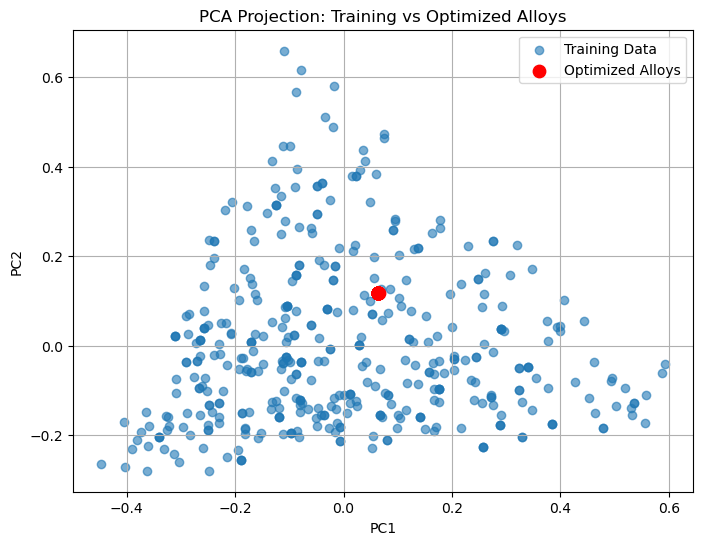

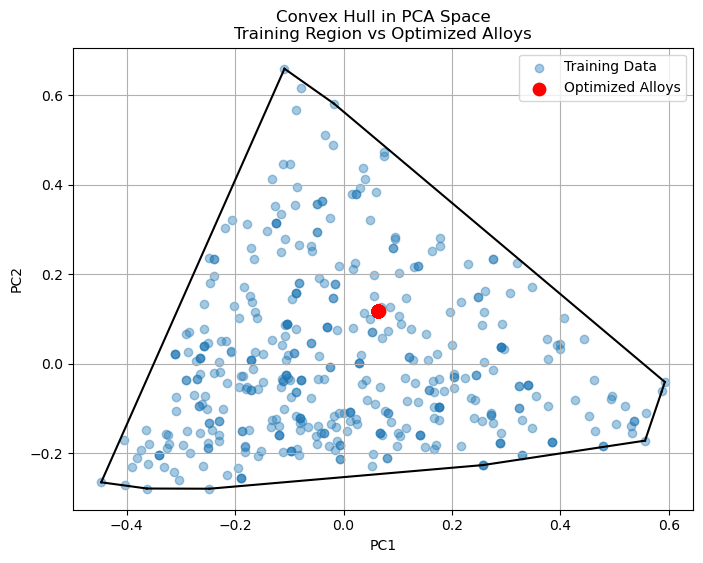

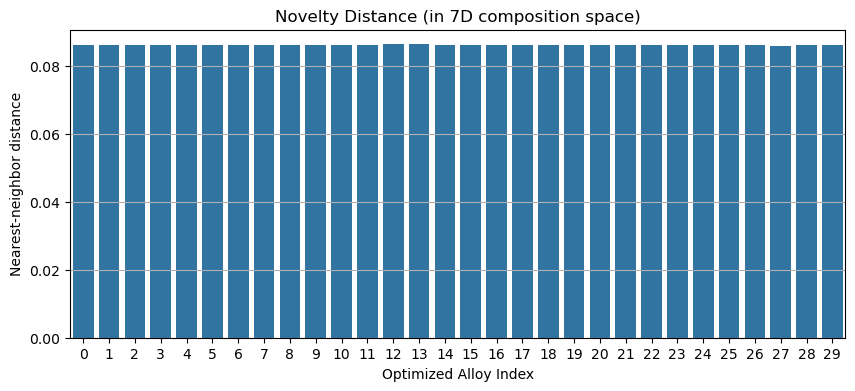

In [12]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# 1. LOAD ORIGINAL DATA
# ==============================
df = pd.read_excel("Composition_SFE_Dataset_old.xlsx")
X_train = df.drop(columns=["SFE"]).values
element_names = df.drop(columns=["SFE"]).columns.tolist()

print("Training data shape:", X_train.shape)

# ==============================
# 2. LOAD OPTIMIZED CANDIDATES
# ==============================
opt = pd.read_excel("GWO_TRIP_TWIP_candidates_7of7.xlsx")
X_opt = opt[element_names].values
print("Optimized candidate shape:", X_opt.shape)

# ==============================
# 3. PCA → 2D PROJECTION
# ==============================
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train)
X_opt_2d = pca.transform(X_opt)

# ==============================
# 4. 2D CONVEX HULL ON TRAINING DATA
# ==============================
hull_2d = ConvexHull(X_train_2d)

def in_hull_2d(point, hull):
    """
    Check if a 2D point lies inside the 2D convex hull.
    point: shape (2,)
    """
    A = hull.equations[:, :2]   # normals
    b = hull.equations[:, 2]    # offsets
    # For points inside hull: A @ x + b <= 0
    return np.all(A.dot(point) + b <= 1e-12)

# ==============================
# 5. NOVELTY METRICS
# ==============================
results = []
for i, (p_full, p_2d) in enumerate(zip(X_opt, X_opt_2d)):
    inside = in_hull_2d(p_2d, hull_2d)

    # distance in ORIGINAL 7D composition space
    d_full = np.min(np.linalg.norm(X_train - p_full, axis=1))

    results.append({
        "index": i,
        "inside_convex_hull_2D": inside,
        "novelty_distance_7D": d_full
    })

novelty_df = pd.DataFrame(results)
final = pd.concat([opt, novelty_df], axis=1)

final.to_excel("Novelty_Analysis_2D_PCA_7.xlsx", index=False)
print("\n=== NOVELTY ANALYSIS (2D PCA hull + 7D distance) DONE ===")
print(final.head())

# =============================================
# 6. PLOT 1 – PCA scatter: train vs optimized
# =============================================
plt.figure(figsize=(8, 6))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1],
            alpha=0.6, label='Training Data')
plt.scatter(X_opt_2d[:, 0], X_opt_2d[:, 1],
            color='red', s=80, label='Optimized Alloys')
plt.title("PCA Projection: Training vs Optimized Alloys")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()

# =============================================
# 7. PLOT 2 – Draw 2D convex hull + optimized pts
# =============================================
plt.figure(figsize=(8, 6))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1],
            alpha=0.4, label='Training Data')

# draw hull edges
for simplex in hull_2d.simplices:
    plt.plot(X_train_2d[simplex, 0], X_train_2d[simplex, 1], 'k-')

plt.scatter(X_opt_2d[:, 0], X_opt_2d[:, 1],
            color='red', s=80, label='Optimized Alloys')

plt.title("Convex Hull in PCA Space\nTraining Region vs Optimized Alloys")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()

# =============================================
# 8. PLOT 3 – Novelty distance bar chart
# =============================================
plt.figure(figsize=(10, 4))
sns.barplot(x=np.arange(len(novelty_df)),
            y=novelty_df["novelty_distance_7D"])
plt.title("Novelty Distance (in 7D composition space)")
plt.xlabel("Optimized Alloy Index")
plt.ylabel("Nearest-neighbor distance")
plt.grid(axis='y')
plt.show()
